# 06 — DESI Figure 1 reproduction diagnostics

This notebook diagnoses why the Monte Carlo bands obtained in Notebook 05 differ from Figure 1 of the paper. It does not rerun PySR and does not modify upstream results.

## 1. Questions addressed

1. Where do denominator crossings occur?
2. How do the bands change when conditioning on pole-free curves?
3. How sensitive are the results to a minimum-denominator threshold?
4. How much uncertainty comes from the DESI data and how much comes from the sound horizon?
5. Which conclusions can be compared with the paper without inventing unreported implementation details?

> Pole-free and thresholded bands are conditional diagnostics. They are not replacements for the unfiltered Monte Carlo result unless a physical selection rule is justified independently.

In [17]:
from pathlib import Path
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 40)

## 2. Upstream experiment and output directory

Change `EXPERIMENT_ID` before testing a new diagnostic definition so that the previous result remains intact.

In [18]:
MONTE_CARLO_EXPERIMENT_ID = "fixed_exponential_20000mc_20260909"
EXPERIMENT_ID = "pole_and_uncertainty_decomposition_20260910"


def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing the Notebook 05 outputs."""
    for candidate in (start, *start.parents):
        source = (
            candidate / "results" / "05_desi_monte_carlo_confidence"
            / MONTE_CARLO_EXPERIMENT_ID / "tables" / "monte_carlo_fit_samples.csv.gz"
        )
        if source.is_file():
            return candidate
    raise FileNotFoundError("Could not locate the Notebook 05 Monte Carlo samples.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
MC_DIR = (
    PROJECT_ROOT / "results" / "05_desi_monte_carlo_confidence"
    / MONTE_CARLO_EXPERIMENT_ID
)
FIT_SAMPLES_FILE = MC_DIR / "tables" / "monte_carlo_fit_samples.csv.gz"
BASELINE_FILE = MC_DIR / "tables" / "deterministic_baselines.csv"
MC_CONFIGURATION_FILE = MC_DIR / "configuration.json"
DATA_FILE = PROJECT_ROOT / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / "results" / "06_desi_fig1_reproduction_diagnostics"
RESULTS_DIR = NOTEBOOK_RESULTS_DIR / EXPERIMENT_ID
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
for directory in (NOTEBOOK_RESULTS_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Input experiment: {MONTE_CARLO_EXPERIMENT_ID}")
print(f"Output experiment: {EXPERIMENT_ID}")
print(f"Output directory: {RESULTS_DIR}")

Input experiment: fixed_exponential_20000mc_20260909
Output experiment: pole_and_uncertainty_decomposition_20260910
Output directory: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910


## 3. Load the saved Monte Carlo parameters

Notebook 05 already performed 80,000 covariance-weighted exponential fits. Reusing the fitted `A`, `B`, and `rd_hinv_mpc` columns keeps this diagnostic separate from the expensive upstream experiment.

In [19]:
fit_samples = pd.read_csv(FIT_SAMPLES_FILE)
baselines = pd.read_csv(BASELINE_FILE)
with np.load(DATA_FILE) as data:
    z_data = data["z"].astype(float)
    y_data = data["y"].astype(float)
    public_sigma = data["sigma"].astype(float)
with MC_CONFIGURATION_FILE.open(encoding="utf-8") as stream:
    mc_configuration = json.load(stream)

required_columns = {
    "covariance", "center_mode", "realization", "A", "B",
    "rd_hinv_mpc", "chi2", "pole_in_0_to_2p5",
}
assert required_columns.issubset(fit_samples.columns)
assert len(fit_samples) == 80_000
assert fit_samples[["A", "B", "rd_hinv_mpc"]].notna().all().all()

group_counts = (fit_samples.groupby(["covariance", "center_mode"])
                .size().rename("realizations").reset_index())
display(group_counts)

,covariance,center_mode,realizations
0,paper_table,observed_data,20000
1,paper_table,paper_expression,20000
2,public_full,observed_data,20000
3,public_full,paper_expression,20000


## 4. Reconstruction and denominator diagnostics

For `D(z) = A exp(B z)`, define `gamma = Omega_m (100 rd / c)^2`. The potentially singular part of Eq. (3) is proportional to

$$g(z)=1-\mathrm{gamma}(1+z)^3D^2(z).$$

A sign change in `g(z)` marks a denominator crossing. The code checks every adjacent pair on a fine redshift grid, allowing more than one crossing to be detected.

In [20]:
PAPER_A, PAPER_B = 28.4, -0.519
OMEGA_M = 0.30
RD_MEAN_HINV_MPC = 101.0
C_KM_S = 299_792.458
Z_GRID = np.linspace(0.0, 2.5, 501)
QUANTILES = np.array([0.1349898, 2.2750132, 15.8655254, 50.0, 84.1344746, 97.7249868, 99.8650102])
QUANTILE_LABELS = ("q0p135", "q2p275", "q15p866", "median", "q84p134", "q97p725", "q99p865")
STABILITY_THRESHOLDS = (0.01, 0.05, 0.10)


def reconstruct(amplitudes, slopes, rd_values, redshift=Z_GRID):
    """Return distance, w(z), and the dimensionless denominator factor."""
    amplitudes = np.asarray(amplitudes, dtype=float)[:, None]
    slopes = np.asarray(slopes, dtype=float)[:, None]
    rd_values = np.asarray(rd_values, dtype=float)[:, None]
    redshift = np.asarray(redshift, dtype=float)[None, :]
    distance = amplitudes * np.exp(slopes * redshift)
    derivative = slopes * distance
    gamma = OMEGA_M * (100.0 * rd_values / C_KM_S) ** 2
    matter_term = gamma * (1.0 + redshift) ** 3 * distance**3
    denominator = 3.0 * (distance - matter_term)
    numerator = 2.0 * (1.0 + redshift) * derivative + 3.0 * matter_term
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        equation_of_state = -1.0 - numerator / denominator
    equation_of_state[~np.isfinite(equation_of_state)] = np.nan
    pole_factor = 1.0 - gamma * (1.0 + redshift) ** 3 * distance**2
    return distance, equation_of_state, pole_factor


def pole_metrics(pole_factor, redshift=Z_GRID):
    """Locate grid-bracketed crossings and minimum absolute denominator factors."""
    signs = pole_factor[:, :-1] * pole_factor[:, 1:] <= 0.0
    crossing_count = signs.sum(axis=1)
    has_pole = crossing_count > 0
    first_pole = np.full(len(pole_factor), np.nan)
    last_pole = np.full(len(pole_factor), np.nan)
    for row_index in np.flatnonzero(has_pole):
        indices = np.flatnonzero(signs[row_index])
        estimates = []
        for grid_index in indices:
            z0, z1 = redshift[grid_index:grid_index + 2]
            f0, f1 = pole_factor[row_index, grid_index:grid_index + 2]
            estimates.append(z0 - f0 * (z1 - z0) / (f1 - f0))
        first_pole[row_index] = estimates[0]
        last_pole[row_index] = estimates[-1]
    return {
        "has_pole": has_pole, "crossing_count": crossing_count,
        "first_pole_redshift": first_pole, "last_pole_redshift": last_pole,
        "minimum_absolute_pole_factor": np.nanmin(np.abs(pole_factor), axis=1),
    }


def curve_quantiles(values):
    """Calculate the standard pointwise one-, two-, and three-sigma quantiles."""
    return np.nanpercentile(values, QUANTILES, axis=0)

## 5. Compute pole locations for all 80,000 realizations

The pole flag saved by Notebook 05 is independently recomputed here. A disagreement would indicate a diagnostic implementation error.

In [21]:
diagnostic_frames = []
for (covariance_name, center_mode), group in fit_samples.groupby(["covariance", "center_mode"], sort=False):
    _, _, pole_factor = reconstruct(group["A"], group["B"], group["rd_hinv_mpc"])
    metrics = pole_metrics(pole_factor)
    diagnosed = group.copy()
    for column, values in metrics.items():
        diagnosed[column] = values
    diagnostic_frames.append(diagnosed)
    print(f"Diagnosed {covariance_name} / {center_mode}")
pole_diagnostics = pd.concat(diagnostic_frames, ignore_index=True)
agreement = (pole_diagnostics["pole_in_0_to_2p5"].astype(bool) == pole_diagnostics["has_pole"]).mean()
assert agreement == 1.0
print(f"Agreement with Notebook 05 pole flag: {agreement:.1%}")

Diagnosed public_full / observed_data
Diagnosed public_full / paper_expression
Diagnosed paper_table / observed_data
Diagnosed paper_table / paper_expression
Agreement with Notebook 05 pole flag: 100.0%


In [22]:
pole_summary_rows = []
for (covariance_name, center_mode), group in pole_diagnostics.groupby(["covariance", "center_mode"]):
    pole_redshifts = group.loc[group["has_pole"], "first_pole_redshift"]
    pole_summary_rows.append({
        "covariance": covariance_name, "center_mode": center_mode,
        "realizations": len(group), "pole_count": int(group["has_pole"].sum()),
        "pole_fraction": group["has_pole"].mean(),
        "first_pole_q2p5": pole_redshifts.quantile(0.025),
        "first_pole_q16": pole_redshifts.quantile(0.16),
        "first_pole_median": pole_redshifts.median(),
        "first_pole_q84": pole_redshifts.quantile(0.84),
        "first_pole_q97p5": pole_redshifts.quantile(0.975),
        "multiple_crossing_fraction": (group["crossing_count"] > 1).mean(),
    })
pole_summary = pd.DataFrame(pole_summary_rows)
display(pole_summary)

,covariance,center_mode,realizations,pole_count,pole_fraction,first_pole_q2p5,first_pole_q16,first_pole_median,first_pole_q84,first_pole_q97p5,multiple_crossing_fraction
0,paper_table,observed_data,20000,3114,0.1557,1.354744,1.485603,1.647280,1.797494,1.915043,0.12595
1,paper_table,paper_expression,20000,1384,0.0692,1.347517,1.478713,1.627003,1.761422,1.876635,0.06455
2,public_full,observed_data,20000,3080,0.1540,1.352257,1.488357,1.648731,1.805309,1.924505,0.12385
3,public_full,paper_expression,20000,1390,0.0695,1.344140,1.474701,1.624193,1.763067,1.872793,0.06475


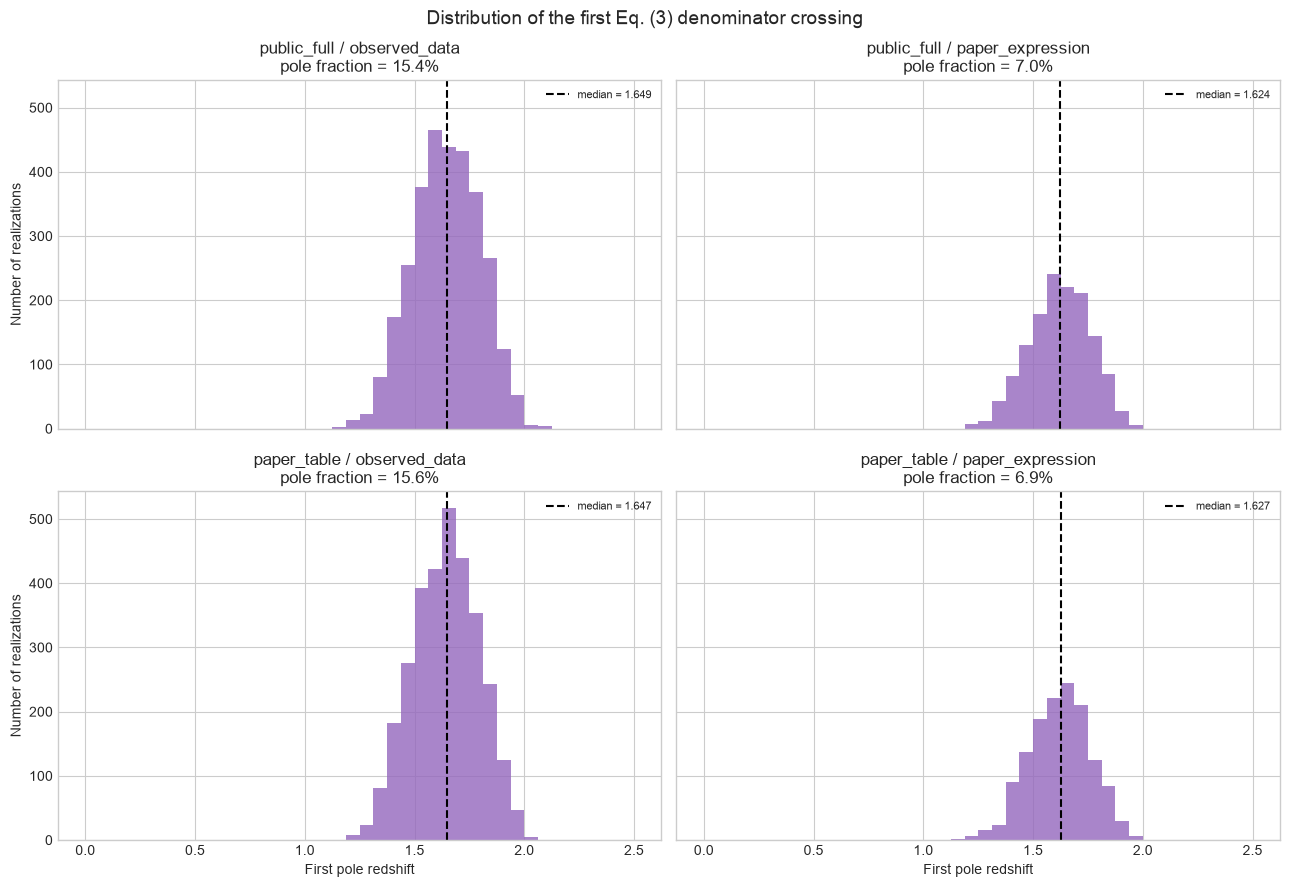

In [23]:
figure, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
for axis, ((covariance_name, center_mode), group) in zip(
    axes.flat, pole_diagnostics.groupby(["covariance", "center_mode"], sort=False)
):
    values = group.loc[group["has_pole"], "first_pole_redshift"]
    axis.hist(values, bins=np.linspace(0.0, 2.5, 41), color="tab:purple", alpha=0.8)
    axis.axvline(values.median(), color="black", ls="--", label=f"median = {values.median():.3f}")
    axis.set_title(f"{covariance_name} / {center_mode}\npole fraction = {group['has_pole'].mean():.1%}")
    axis.legend(fontsize=8)
for axis in axes[-1]:
    axis.set_xlabel("First pole redshift")
for axis in axes[:, 0]:
    axis.set_ylabel("Number of realizations")
figure.suptitle("Distribution of the first Eq. (3) denominator crossing", fontsize=14)
figure.tight_layout()
POLE_FIGURE = FIGURES_DIR / "pole_redshift_distribution.png"
figure.savefig(POLE_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

## 6. All-sample, pole-free, and denominator-threshold selections

Five pre-declared selections are compared. The thresholds were specified before viewing the resulting bands and are treated only as sensitivity tests.

In [24]:
conditional_band_records = []
selection_summary_rows = []
conditional_arrays = {}
for (covariance_name, center_mode), group in pole_diagnostics.groupby(["covariance", "center_mode"], sort=False):
    selections = {
        "all": np.ones(len(group), dtype=bool),
        "pole_free": ~group["has_pole"].to_numpy(),
        **{
            f"stable_eps_{epsilon:.2f}": (~group["has_pole"].to_numpy())
            & (group["minimum_absolute_pole_factor"].to_numpy() > epsilon)
            for epsilon in STABILITY_THRESHOLDS
        },
    }
    for selection_name, mask in selections.items():
        selected = group.loc[mask]
        distance, w_values, _ = reconstruct(selected["A"], selected["B"], selected["rd_hinv_mpc"])
        distance_q, w_q = curve_quantiles(distance), curve_quantiles(w_values)
        key = (covariance_name, center_mode, selection_name)
        conditional_arrays[key] = {"distance": distance_q, "w": w_q}
        selection_summary_rows.append({
            "covariance": covariance_name, "center_mode": center_mode,
            "selection": selection_name, "retained": len(selected),
            "retained_fraction": len(selected) / len(group),
            "maximum_1sigma_w_width": np.nanmax(w_q[4] - w_q[2]),
            "maximum_2sigma_w_width": np.nanmax(w_q[5] - w_q[1]),
            "maximum_3sigma_w_width": np.nanmax(w_q[6] - w_q[0]),
        })
        for grid_index, redshift in enumerate(Z_GRID):
            row = {"covariance": covariance_name, "center_mode": center_mode,
                   "selection": selection_name, "z": redshift}
            for q_index, label in enumerate(QUANTILE_LABELS):
                row[f"distance_{label}"] = distance_q[q_index, grid_index]
                row[f"w_{label}"] = w_q[q_index, grid_index]
            conditional_band_records.append(row)
selection_summary = pd.DataFrame(selection_summary_rows)
conditional_bands = pd.DataFrame(conditional_band_records)
display(selection_summary)

,covariance,center_mode,selection,retained,retained_fraction,maximum_1sigma_w_width,maximum_2sigma_w_width,maximum_3sigma_w_width
0,public_full,observed_data,all,20000,1.00000,2.543916,29.641398,634.957477
1,public_full,observed_data,pole_free,16920,0.84600,1.838241,6.143776,37.140611
2,public_full,observed_data,stable_eps_0.01,15803,0.79015,1.473292,3.063065,4.689949
3,public_full,observed_data,stable_eps_0.05,9728,0.48640,0.628644,1.081111,1.527645
4,public_full,observed_data,stable_eps_0.10,2518,0.12590,0.300508,0.607890,0.910669
5,public_full,paper_expression,all,20000,1.00000,1.636335,14.175206,319.075802
6,public_full,paper_expression,pole_free,18610,0.93050,1.392275,4.531458,20.325859
7,public_full,paper_expression,stable_eps_0.01,17943,0.89715,1.241899,2.872456,4.245285
8,public_full,paper_expression,stable_eps_0.05,12974,0.64870,0.646945,1.095301,1.471876
9,public_full,paper_expression,stable_eps_0.10,4593,0.22965,0.297693,0.601198,0.866734


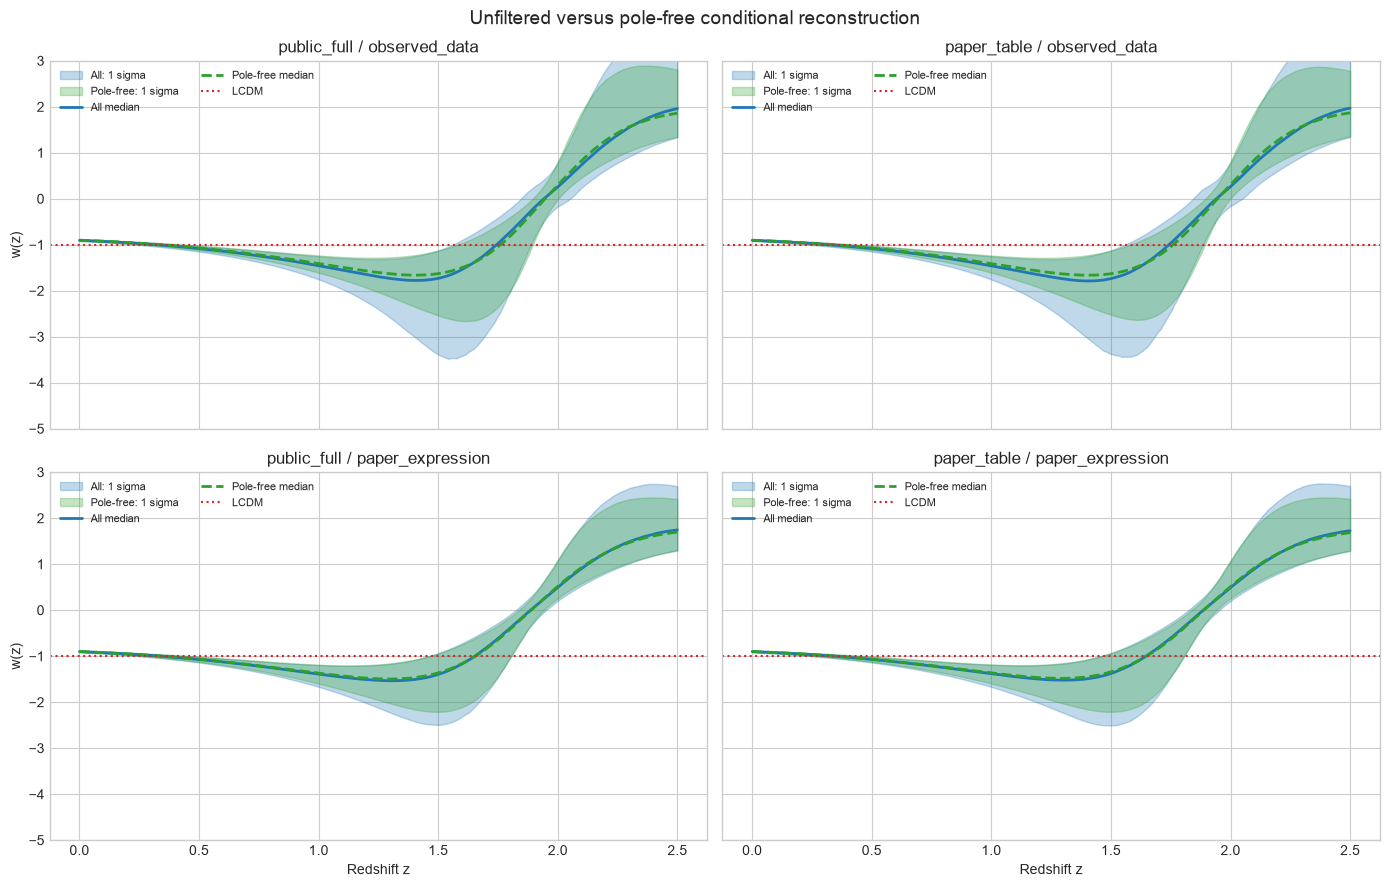

In [25]:
figure, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for row_index, center_mode in enumerate(("observed_data", "paper_expression")):
    for column_index, covariance_name in enumerate(("public_full", "paper_table")):
        axis = axes[row_index, column_index]
        all_q = conditional_arrays[(covariance_name, center_mode, "all")]["w"]
        pole_free_q = conditional_arrays[(covariance_name, center_mode, "pole_free")]["w"]
        axis.fill_between(Z_GRID, all_q[2], all_q[4], color="tab:blue", alpha=0.28, label="All: 1 sigma")
        axis.fill_between(Z_GRID, pole_free_q[2], pole_free_q[4], color="tab:green", alpha=0.28, label="Pole-free: 1 sigma")
        axis.plot(Z_GRID, all_q[3], color="tab:blue", lw=2, label="All median")
        axis.plot(Z_GRID, pole_free_q[3], color="tab:green", lw=2, ls="--", label="Pole-free median")
        axis.axhline(-1.0, color="tab:red", ls=":", label="LCDM")
        axis.set_title(f"{covariance_name} / {center_mode}")
        axis.set_ylim(-5.0, 3.0)
        axis.legend(fontsize=8, ncol=2)
for axis in axes[-1]:
    axis.set_xlabel("Redshift z")
for axis in axes[:, 0]:
    axis.set_ylabel("w(z)")
figure.suptitle("Unfiltered versus pole-free conditional reconstruction", fontsize=14)
figure.tight_layout()
CONDITIONAL_FIGURE = FIGURES_DIR / "all_vs_pole_free_bands.png"
figure.savefig(CONDITIONAL_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

## 7. Figure 1 candidate conditional on minimum absolute g(z) > 0.01

This diagnostic uses the existing paper-expression-centered, public-covariance samples. It does not redraw or replenish rejected samples. The resulting bands are explicitly conditional on the pre-declared denominator-stability rule and are not presented as the unfiltered Monte Carlo confidence interval.

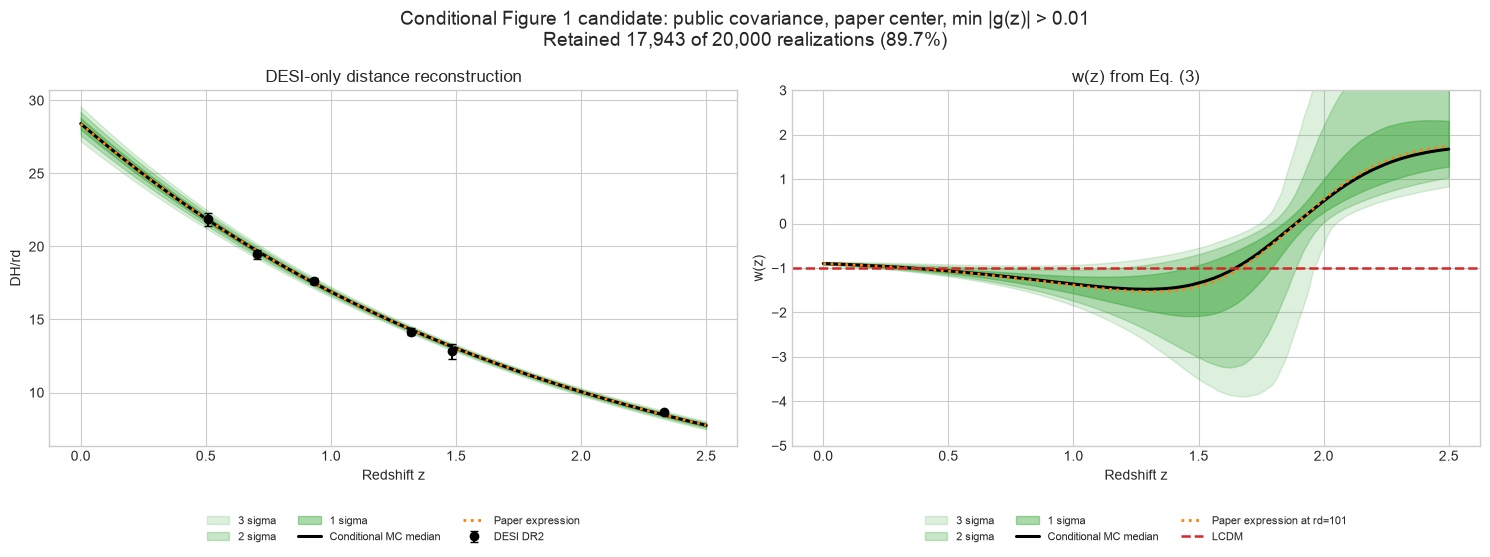

Saved conditional candidate: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/figures/paper_centered_public_eps0p01_candidate.png


In [26]:
CANDIDATE_SELECTION = "stable_eps_0.01"
candidate = conditional_arrays[("public_full", "paper_expression", CANDIDATE_SELECTION)]
distance_q, w_q = candidate["distance"], candidate["w"]
paper_distance, paper_w, _ = reconstruct([PAPER_A], [PAPER_B], [RD_MEAN_HINV_MPC])
paper_distance, paper_w = paper_distance[0], paper_w[0]
candidate_count = int(selection_summary.query(
    "covariance == 'public_full' and center_mode == 'paper_expression' and selection == @CANDIDATE_SELECTION"
)["retained"].iloc[0])

figure, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for low, high, alpha_value, label in ((0, 6, 0.16, "3 sigma"), (1, 5, 0.26, "2 sigma"), (2, 4, 0.40, "1 sigma")):
    axes[0].fill_between(Z_GRID, distance_q[low], distance_q[high], color="tab:green", alpha=alpha_value, label=label)
    axes[1].fill_between(Z_GRID, w_q[low], w_q[high], color="tab:green", alpha=alpha_value, label=label)
axes[0].plot(Z_GRID, distance_q[3], color="black", lw=2.2, label="Conditional MC median")
axes[0].plot(Z_GRID, paper_distance, color="tab:orange", ls=":", lw=2, label="Paper expression")
axes[0].errorbar(z_data, y_data, yerr=public_sigma, fmt="o", color="black", capsize=3, label="DESI DR2")
axes[1].plot(Z_GRID, w_q[3], color="black", lw=2.2, label="Conditional MC median")
axes[1].plot(Z_GRID, paper_w, color="tab:orange", ls=":", lw=2, label="Paper expression at rd=101")
axes[1].axhline(-1.0, color="tab:red", ls="--", lw=1.8, label="LCDM")
axes[0].set(title="DESI-only distance reconstruction", xlabel="Redshift z", ylabel="DH/rd")
axes[1].set(title="w(z) from Eq. (3)", xlabel="Redshift z", ylabel="w(z)", ylim=(-5.0, 3.0))
for axis in axes:
    axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8)
figure.suptitle(
    f"Conditional Figure 1 candidate: public covariance, paper center, min |g(z)| > 0.01\n"
    f"Retained {candidate_count:,} of 20,000 realizations ({candidate_count / 20_000:.1%})",
    fontsize=14,
)
figure.tight_layout()
CANDIDATE_FIGURE = FIGURES_DIR / "paper_centered_public_eps0p01_candidate.png"
figure.savefig(CANDIDATE_FIGURE, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved conditional candidate: {CANDIDATE_FIGURE}")

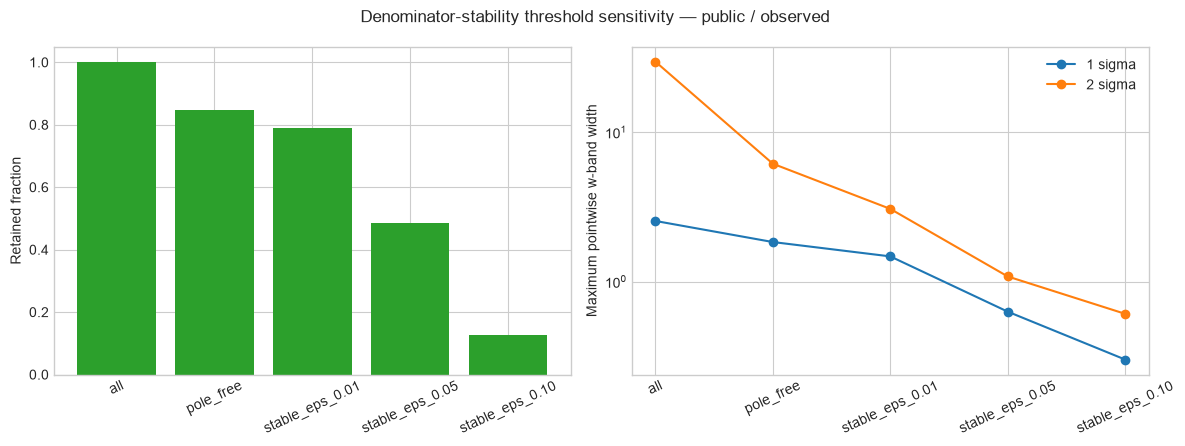

In [27]:
public_observed = selection_summary.query(
    "covariance == 'public_full' and center_mode == 'observed_data'"
).copy()
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(public_observed["selection"], public_observed["retained_fraction"], color="tab:green")
axes[0].set_ylabel("Retained fraction")
axes[0].set_ylim(0, 1.05)
axes[1].plot(public_observed["selection"], public_observed["maximum_1sigma_w_width"], "o-", label="1 sigma")
axes[1].plot(public_observed["selection"], public_observed["maximum_2sigma_w_width"], "o-", label="2 sigma")
axes[1].set_yscale("log")
axes[1].set_ylabel("Maximum pointwise w-band width")
axes[1].legend()
for axis in axes:
    axis.tick_params(axis="x", rotation=25)
figure.suptitle("Denominator-stability threshold sensitivity — public / observed")
figure.tight_layout()
THRESHOLD_FIGURE = FIGURES_DIR / "stability_threshold_comparison.png"
figure.savefig(THRESHOLD_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

## 8. Decompose data and sound-horizon uncertainty

`data_only` keeps the fitted Monte Carlo values of `A` and `B` but fixes `rd=101`. `rd_only` fixes the central exponential parameters and varies only the saved sound-horizon draws. `combined` uses all saved values. This is a controlled decomposition, not a claim that nonlinear variances add independently.

In [28]:
baseline_parameters = {
    row["covariance"]: (float(row["A"]), float(row["B"]))
    for _, row in baselines.iterrows()
}
decomposition_records = []
decomposition_summary_rows = []
decomposition_arrays = {}
for (covariance_name, center_mode), group in pole_diagnostics.groupby(["covariance", "center_mode"], sort=False):
    if center_mode == "paper_expression":
        central_A, central_B = PAPER_A, PAPER_B
    else:
        central_A, central_B = baseline_parameters[covariance_name]
    variants = {
        "data_only": (group["A"].to_numpy(), group["B"].to_numpy(), np.full(len(group), RD_MEAN_HINV_MPC)),
        "rd_only": (np.full(len(group), central_A), np.full(len(group), central_B), group["rd_hinv_mpc"].to_numpy()),
        "combined": (group["A"].to_numpy(), group["B"].to_numpy(), group["rd_hinv_mpc"].to_numpy()),
    }
    for source_name, (amplitudes, slopes, rd_values) in variants.items():
        _, w_values, pole_factor = reconstruct(amplitudes, slopes, rd_values)
        metrics = pole_metrics(pole_factor)
        w_q = curve_quantiles(w_values)
        decomposition_arrays[(covariance_name, center_mode, source_name)] = w_q
        decomposition_summary_rows.append({
            "covariance": covariance_name, "center_mode": center_mode,
            "uncertainty_source": source_name, "pole_fraction": metrics["has_pole"].mean(),
            "maximum_1sigma_w_width": np.nanmax(w_q[4] - w_q[2]),
            "maximum_2sigma_w_width": np.nanmax(w_q[5] - w_q[1]),
        })
        for grid_index, redshift in enumerate(Z_GRID):
            row = {"covariance": covariance_name, "center_mode": center_mode,
                   "uncertainty_source": source_name, "z": redshift}
            for q_index, label in enumerate(QUANTILE_LABELS):
                row[f"w_{label}"] = w_q[q_index, grid_index]
            decomposition_records.append(row)
decomposition_summary = pd.DataFrame(decomposition_summary_rows)
uncertainty_decomposition = pd.DataFrame(decomposition_records)
display(decomposition_summary)

,covariance,center_mode,uncertainty_source,pole_fraction,maximum_1sigma_w_width,maximum_2sigma_w_width
0,public_full,observed_data,data_only,0.00300,1.178342,3.111585
1,public_full,observed_data,rd_only,0.13550,2.537281,28.874314
2,public_full,observed_data,combined,0.15400,2.543916,29.641398
3,public_full,paper_expression,data_only,0.00000,0.689828,1.512449
4,public_full,paper_expression,rd_only,0.05640,1.600455,12.633532
5,public_full,paper_expression,combined,0.06950,1.636335,14.175206
6,paper_table,observed_data,data_only,0.00275,1.151173,3.087420
7,paper_table,observed_data,rd_only,0.14075,2.528134,29.746786
8,paper_table,observed_data,combined,0.15570,2.518628,31.512156
9,paper_table,paper_expression,data_only,0.00000,0.686363,1.493836


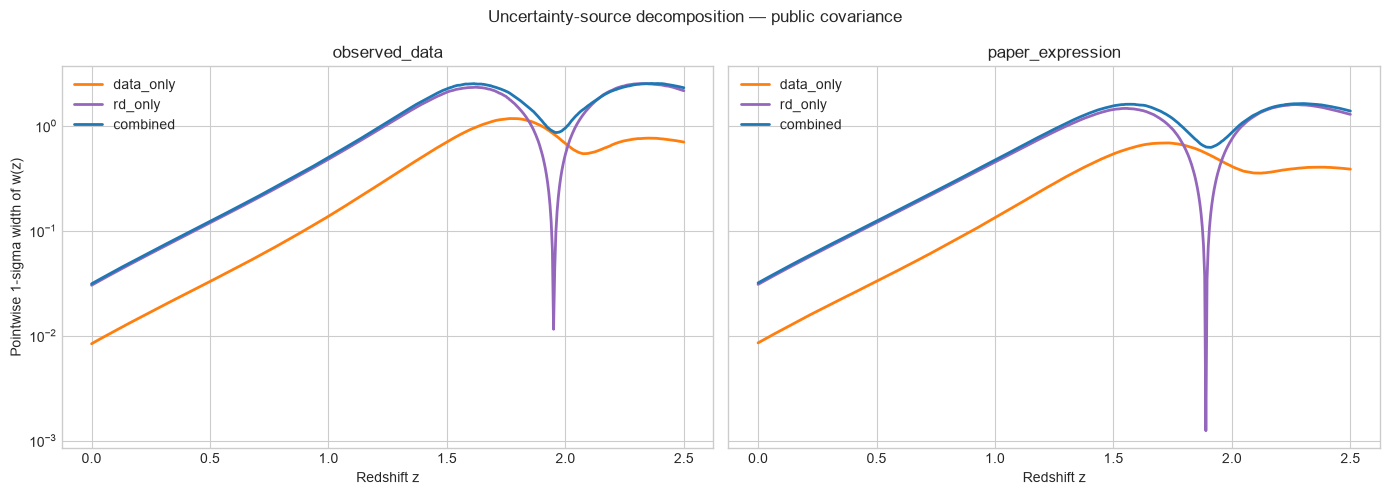

In [29]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
colors = {"data_only": "tab:orange", "rd_only": "tab:purple", "combined": "tab:blue"}
for axis, center_mode in zip(axes, ("observed_data", "paper_expression")):
    for source_name in ("data_only", "rd_only", "combined"):
        q = decomposition_arrays[("public_full", center_mode, source_name)]
        axis.plot(Z_GRID, q[4] - q[2], color=colors[source_name], lw=2, label=source_name)
    axis.set_yscale("log")
    axis.set_title(center_mode)
    axis.set_xlabel("Redshift z")
    axis.legend()
axes[0].set_ylabel("Pointwise 1-sigma width of w(z)")
figure.suptitle("Uncertainty-source decomposition — public covariance")
figure.tight_layout()
DECOMPOSITION_FIGURE = FIGURES_DIR / "uncertainty_source_comparison.png"
figure.savefig(DECOMPOSITION_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

## 9. Selected-redshift comparison table

Band widths are evaluated at fixed redshifts. This avoids relying only on the appearance of a plot and provides values that can later be compared with a digitized version of Figure 1.

In [30]:
SELECTED_REDSHIFTS = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5])
selected_rows = []
for key, arrays in conditional_arrays.items():
    covariance_name, center_mode, selection_name = key
    q = arrays["w"]
    for requested_z in SELECTED_REDSHIFTS:
        index = int(np.argmin(np.abs(Z_GRID - requested_z)))
        selected_rows.append({
            "covariance": covariance_name, "center_mode": center_mode,
            "selection": selection_name, "z": Z_GRID[index],
            "w_median": q[3, index],
            "width_1sigma": q[4, index] - q[2, index],
            "width_2sigma": q[5, index] - q[1, index],
            "width_3sigma": q[6, index] - q[0, index],
            "lcdm_in_1sigma": bool(q[2, index] <= -1.0 <= q[4, index]),
            "lcdm_in_2sigma": bool(q[1, index] <= -1.0 <= q[5, index]),
            "lcdm_in_3sigma": bool(q[0, index] <= -1.0 <= q[6, index]),
        })
selected_redshift_widths = pd.DataFrame(selected_rows)
display(selected_redshift_widths.query(
    "covariance == 'public_full' and center_mode == 'observed_data' and selection in ['all', 'pole_free']"
))

,covariance,center_mode,selection,z,w_median,width_1sigma,width_2sigma,width_3sigma,lcdm_in_1sigma,lcdm_in_2sigma,lcdm_in_3sigma
0,public_full,observed_data,all,0.0,-0.904566,0.031286,0.063062,0.096693,False,False,False
1,public_full,observed_data,all,0.5,-1.083473,0.123137,0.251333,0.392558,False,True,True
2,public_full,observed_data,all,1.0,-1.455966,0.501445,1.110523,2.075345,False,False,True
3,public_full,observed_data,all,1.5,-1.732036,2.261488,17.331145,312.248216,False,True,True
4,public_full,observed_data,all,2.0,0.254709,0.956144,7.479111,132.076477,False,True,True
5,public_full,observed_data,all,2.5,1.957955,2.316365,18.176128,440.862518,False,True,True
6,public_full,observed_data,pole_free,0.0,-0.901515,0.025825,0.047729,0.067898,False,False,False
7,public_full,observed_data,pole_free,0.5,-1.071835,0.099441,0.182197,0.255692,False,True,True
8,public_full,observed_data,pole_free,1.0,-1.410011,0.375131,0.669738,0.896587,False,False,True
9,public_full,observed_data,pole_free,1.5,-1.629699,1.410035,2.737771,3.746213,False,True,True


## 10. Paper Figure 1 comparison boundary

The paper reports Gaussian Monte Carlo bands centered on the best-fit PySR expression, but it does not tabulate their numerical boundaries or fully define the reconstruction uncertainties. Therefore no numerical paper band is invented here. A CSV template is saved for later digitization.

The paper-expression / public-covariance result is the primary stated-method comparison. The pole-free result is reported only as a conditional diagnostic.

In [31]:
paper_figure1_template = pd.DataFrame({
    "z": SELECTED_REDSHIFTS,
    "paper_w_central": np.nan,
    "paper_w_1sigma_low": np.nan, "paper_w_1sigma_high": np.nan,
    "paper_w_2sigma_low": np.nan, "paper_w_2sigma_high": np.nan,
    "paper_w_3sigma_low": np.nan, "paper_w_3sigma_high": np.nan,
    "digitization_note": "Not digitized; do not use for numerical comparison",
})
display(paper_figure1_template)

,z,paper_w_central,paper_w_1sigma_low,paper_w_1sigma_high,paper_w_2sigma_low,paper_w_2sigma_high,paper_w_3sigma_low,paper_w_3sigma_high,digitization_note
0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not digitized; do not use for numerical compar...
1,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not digitized; do not use for numerical compar...
2,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not digitized; do not use for numerical compar...
3,1.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not digitized; do not use for numerical compar...
4,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not digitized; do not use for numerical compar...
5,2.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not digitized; do not use for numerical compar...


## 11. Save all diagnostics

The output configuration records all thresholds and labels the filtered products as conditional results.

In [32]:
POLE_DIAGNOSTICS_FILE = TABLES_DIR / "pole_diagnostics.csv.gz"
POLE_SUMMARY_FILE = TABLES_DIR / "pole_summary.csv"
CONDITIONAL_BANDS_FILE = TABLES_DIR / "conditional_bands.csv.gz"
SELECTION_SUMMARY_FILE = TABLES_DIR / "selection_summary.csv"
DECOMPOSITION_FILE = TABLES_DIR / "uncertainty_decomposition.csv.gz"
DECOMPOSITION_SUMMARY_FILE = TABLES_DIR / "uncertainty_decomposition_summary.csv"
SELECTED_WIDTHS_FILE = TABLES_DIR / "selected_redshift_widths.csv"
PAPER_TEMPLATE_FILE = TABLES_DIR / "paper_figure1_digitization_template.csv"
CONFIGURATION_FILE = RESULTS_DIR / "configuration.json"

pole_diagnostics.to_csv(POLE_DIAGNOSTICS_FILE, index=False, compression="gzip")
pole_summary.to_csv(POLE_SUMMARY_FILE, index=False)
conditional_bands.to_csv(CONDITIONAL_BANDS_FILE, index=False, compression="gzip")
selection_summary.to_csv(SELECTION_SUMMARY_FILE, index=False)
uncertainty_decomposition.to_csv(DECOMPOSITION_FILE, index=False, compression="gzip")
decomposition_summary.to_csv(DECOMPOSITION_SUMMARY_FILE, index=False)
selected_redshift_widths.to_csv(SELECTED_WIDTHS_FILE, index=False)
paper_figure1_template.to_csv(PAPER_TEMPLATE_FILE, index=False)

configuration = {
    "experiment_id": EXPERIMENT_ID,
    "source_monte_carlo_experiment": MONTE_CARLO_EXPERIMENT_ID,
    "number_of_source_samples": len(fit_samples),
    "omega_m_fixed": OMEGA_M, "rd_mean_hinv_mpc": RD_MEAN_HINV_MPC,
    "redshift_grid": {"minimum": 0.0, "maximum": 2.5, "points": len(Z_GRID)},
    "stability_thresholds": list(STABILITY_THRESHOLDS),
    "pointwise_quantiles_percent": QUANTILES.tolist(),
    "filtered_result_interpretation": (
        "Pole-free and minimum-denominator selections are conditional diagnostics, "
        "not unqualified confidence intervals."
    ),
    "paper_band_status": "Numerical Figure 1 boundaries not reported; digitization template left empty.",
    "software_versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
    },
}
with CONFIGURATION_FILE.open("w", encoding="utf-8") as stream:
    json.dump(configuration, stream, indent=2)

saved_paths = [
    POLE_DIAGNOSTICS_FILE, POLE_SUMMARY_FILE, CONDITIONAL_BANDS_FILE,
    SELECTION_SUMMARY_FILE, DECOMPOSITION_FILE, DECOMPOSITION_SUMMARY_FILE,
    SELECTED_WIDTHS_FILE, PAPER_TEMPLATE_FILE, CONFIGURATION_FILE,
    POLE_FIGURE, CONDITIONAL_FIGURE, CANDIDATE_FIGURE,
    THRESHOLD_FIGURE, DECOMPOSITION_FIGURE,
]
for path in saved_paths:
    print(f"Saved: {path}")

Saved: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/tables/pole_diagnostics.csv.gz
Saved: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/tables/pole_summary.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/tables/conditional_bands.csv.gz
Saved: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/tables/selection_summary.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/tables/uncertainty_decomposition.csv.gz
Saved: /Users/kemingliu/Desktop/Dark Energy/results/06_desi_fig1_reproduction_diagnostics/pole_and_uncertainty_decomposition_20260910/tables/uncertainty_decomposition_summary

## 12. Observed findings

- The public and paper-table covariance configurations give nearly identical pole fractions and pole-redshift distributions. Covariance rounding is therefore not the main source of the Figure 1 discrepancy.
- The pole fraction is about 15.4%–15.6% for observed-data-centered simulations and about 6.9%–7.0% for paper-expression-centered simulations.
- The median first crossing occurs near `z = 1.62–1.65`. Many pole-producing curves cross twice because the denominator factor can return to the same sign at higher redshift.
- Conditioning only on no crossing retains about 84.5% of observed-centered samples and about 93.1% of paper-centered samples. It reduces the extreme tails but does not eliminate near-singular curves.
- The dedicated Figure 1 candidate conditioned on `min |g(z)| > 0.01` retains 17,943 of 20,000 paper-centered/public-covariance realizations (89.7%). It is reported as a conditional diagnostic rather than an unqualified reproduction.
- For public / observed simulations, the maximum pointwise 2-sigma width falls from about 29.6 for all samples to 6.14 for pole-free samples. Requiring a minimum denominator factor above 0.05 reduces it to about 1.08 but retains only 48.6% of samples. This threshold is too influential to adopt without an independent physical justification.
- The uncertainty decomposition shows that sound-horizon uncertainty dominates the largest high-redshift band width in the present implementation. For public / observed simulations, `rd_only` produces a 13.6% pole fraction, compared with 0.3% for `data_only`.
- The published Figure 1 cannot yet be classified as an exact reproduction because its numerical band boundaries and singular-curve treatment are not reported. The present status is a partial reproduction with an identified denominator-instability mechanism.

## 13. Evaluation rules

- If the public and paper-table results remain similar, covariance rounding is not the primary Figure 1 discrepancy.
- If pole-free bands become smooth, singular realizations explain the irregular high-redshift tails, but filtering still requires an independent physical justification.
- If `data_only` dominates, the DESI measurement uncertainty drives the reconstruction. If `rd_only` dominates, the sound-horizon prior drives it.
- A paper-like visual match obtained only after an undocumented filter is a conditional reproduction, not an exact reproduction.
- Pointwise inclusion of `w=-1` is not a global significance test.

The next decision is based on these diagnostics: classify Figure 1 as exact, partial, conditional, or not uniquely reproducible before moving to the supernova datasets.